In [1]:
import seaborn as sns
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

In [3]:
from sklearn.model_selection import train_test_split as tts

In [4]:
df = sns.load_dataset('iris')

In [5]:
df.head(3)

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa


In [6]:
encoder = LabelEncoder()
df['species'] = encoder.fit_transform(df['species'])

In [7]:
df.head(3)

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0


In [8]:
df.sample(4)

,sepal_length,sepal_width,petal_length,petal_width,species
84,5.4,3.0,4.5,1.5,1
144,6.7,3.3,5.7,2.5,2
2,4.7,3.2,1.3,0.2,0
57,4.9,2.4,3.3,1.0,1


In [9]:
df = df[['sepal_length', 'petal_length', 'species']]

In [10]:
df.head(2)

,sepal_length,petal_length,species
0,5.1,1.4,0
1,4.9,1.4,0


In [11]:
X=df.iloc[:,0:2]
y=df.iloc[:, -1]

In [12]:
X_train,X_test, y_train,y_test=tts(X,y, test_size=0.2, random_state=2)

In [13]:
clf = LogisticRegression(multi_class='multinomial')

In [14]:
clf.fit(X_train,y_train)

C:\Users\dell\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


LogisticRegression(multi_class='multinomial')

In [15]:
y_pred = clf.predict(X_test)

In [16]:
print(accuracy_score(y_test,y_pred))

0.9666666666666667


In [17]:
pd.DataFrame(confusion_matrix(y_test, y_pred))

,0,1,2
0,14,0,0
1,0,7,1
2,0,0,8


In [18]:
query=np.array([[3.4, 2.7]])
clf.predict_proba(query)

C:\Users\dell\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([[7.25865651e-01, 2.73720718e-01, 4.13631316e-04]])

In [19]:
clf.predict(query)

C:\Users\dell\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([0])

In [21]:
!pip install mlxtend

  Obtaining dependency information for mlxtend from https://files.pythonhosted.org/packages/1c/07/512f6a780239ad6ce06ce2aa7b4067583f5ddcfc7703a964a082c706a070/mlxtend-0.23.1-py3-none-any.whl.metadata
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
    --------------------------------------- 0.0/1.4 MB ? eta -:--:--
   - -------------------------------------- 0.1/1.4 MB 787.7 kB/s eta 0:00:02
   -- ------------------------------------- 0.1/1.4 MB 991.0 kB/s eta 0:00:02
   ----- ---------------------------------- 0.2/1.4 MB 1.3 MB/s eta 0:00:01
   ------- -------------------------------- 0.3/1.4 MB 1.2 MB/s eta 0:00:01
   ------------- -------------------------- 0.5/1.4 MB 1.8 MB/s eta 0:00:01
   --------------- ------------------------ 0.6/1.4 MB 1.9 MB/s eta 0:00:01
   ----------------------- ---------------- 0.8/1.4 MB 2.3 MB/s eta 0:00:01
   ------------------------------ --------- 1.1/1.4 MB 2.7 MB/s eta 0:00:01
   ------------------------------------- -- 1.4/1.

C:\Users\dell\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


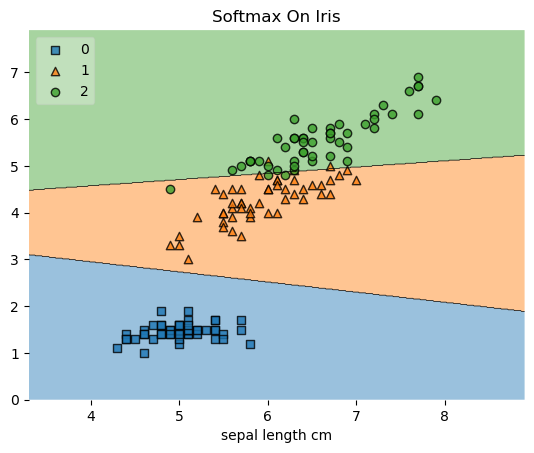

In [23]:
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(X.values,y.values, clf, legend=2)
plt.xlabel('sepal length cm')
plt.xlabel('sepal length cm')
plt.title('Softmax On Iris')
plt.show()